# TP4: Training with SGD, Mini-batches and Momentum

A typical training pipeline:
* Prepare the dataset: split it, normalize it to zero mean and unit variance.
* Define the model, the loss function and the optimizer; initialize the parameters.
* Loop until a stopping criterion:
  * take a mini-batch of data;
  * compute the forward pass;
  * compute the loss on the predictions and the labels;
  * update the parameters with the optimizer.
* Tune the hyperparameters: learning rate, batch size, number of epochs, optimizer.

PyTorch gives one object for each part (`DataLoader`, `nn.Module`, loss, `optim`), so we can change one part and keep the others.

**This TP**
1. **Follow along (Parts 0–4).** On a toy problem, train the same model three ways: SGD with **1 example per update**, **mini-batch** SGD, and mini-batch SGD with **momentum**. Then compare the three on one figure. Part 4 prepares MNIST for the exercises.
2. **Exercises (to submit).** On MNIST, and optionally CIFAR-10: experiment with the learning rate, the batch size, momentum and other optimizers, learning rate schedules and batch normalization. After each experiment, write what you observe and explain it in the cell.

**Runtime:** Colab with a GPU (Runtime → Change runtime type → T4 GPU).

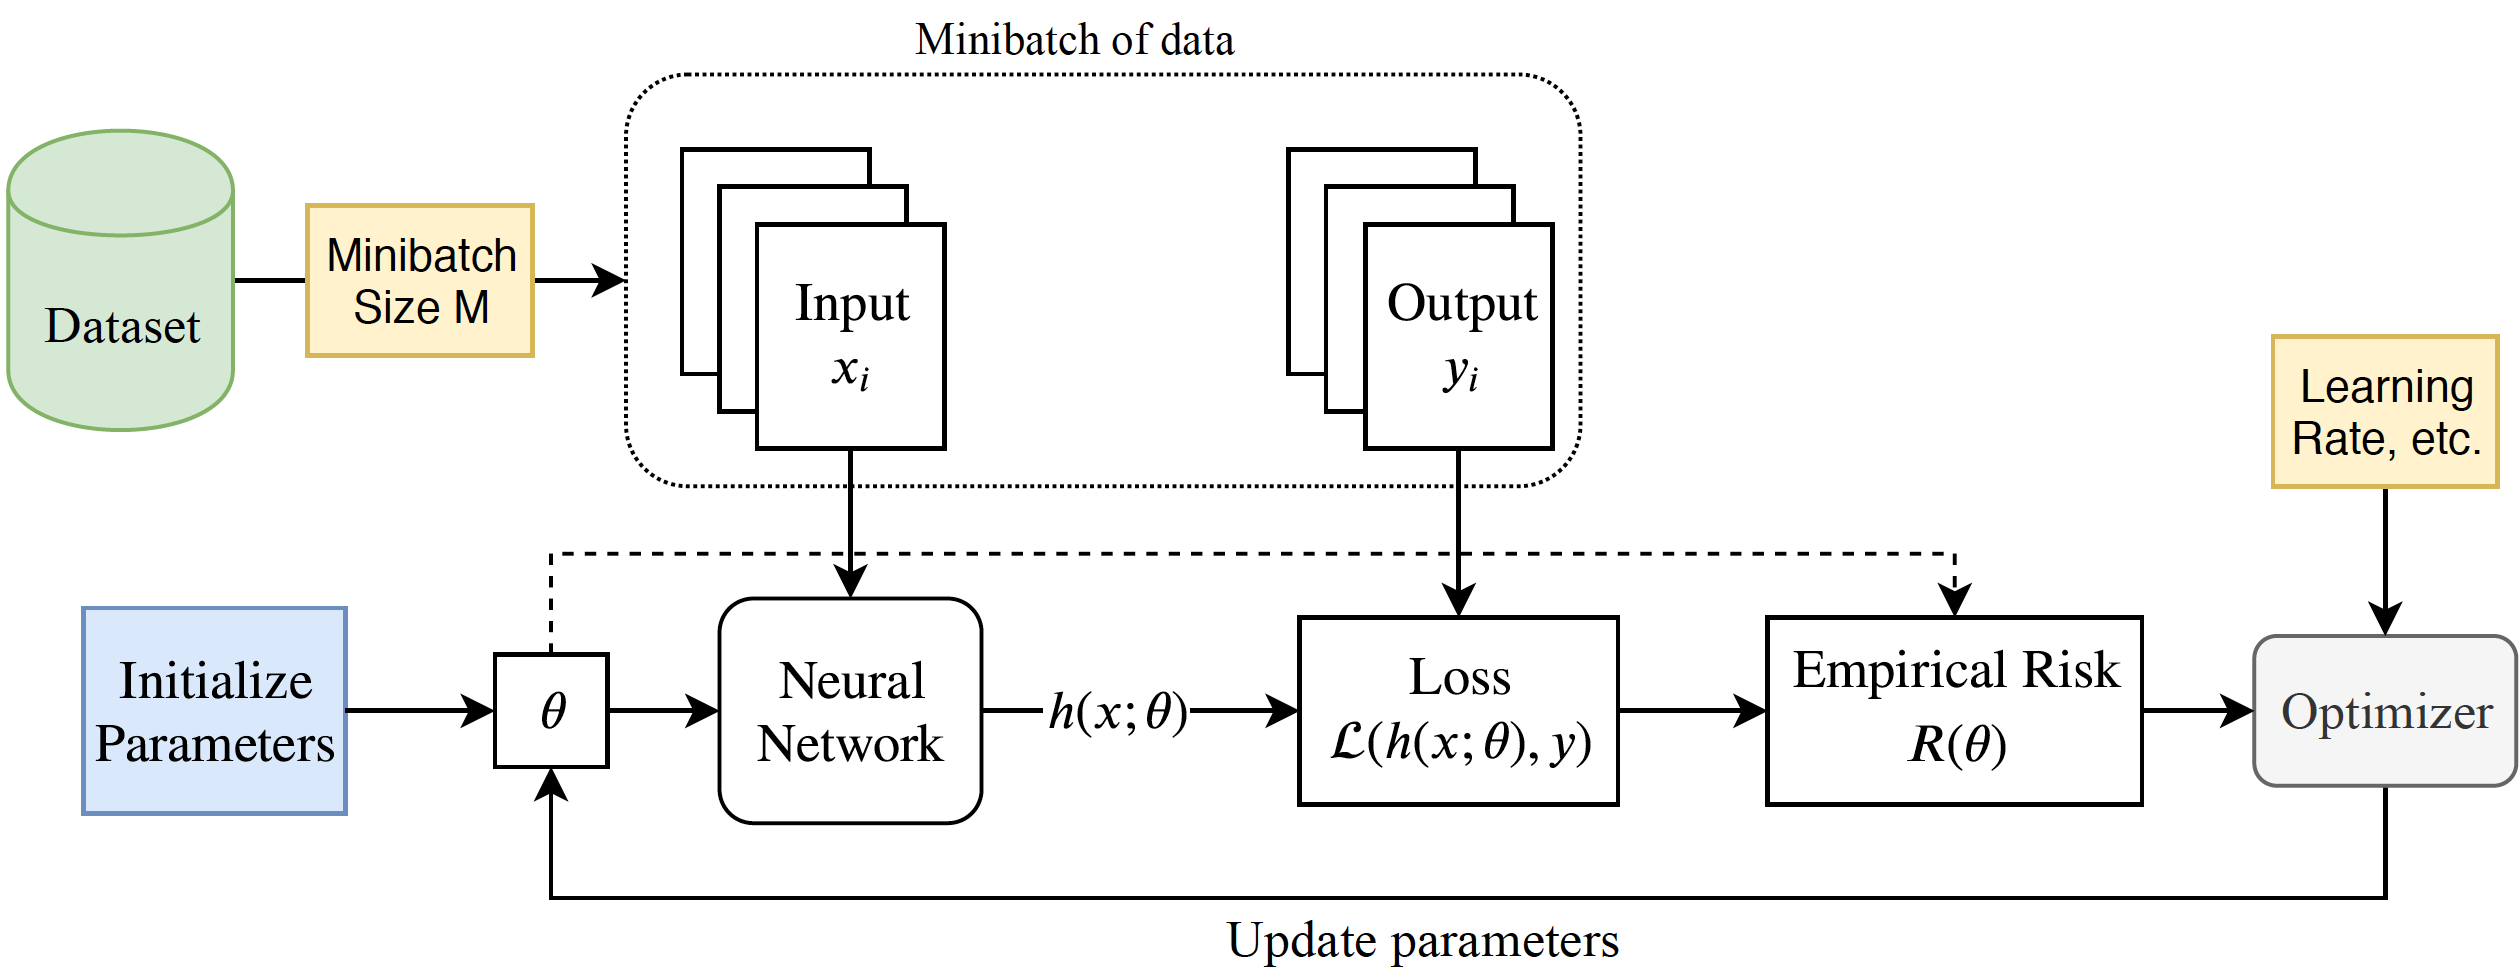

## 0 · Setup

In [ ]:
import math, time, random
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import matplotlib.pyplot as plt

SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cu130 | device: cuda


## 1 · A toy problem: linear regression

1,000 points $(x, y)$ with $y = 3x + 2 + \text{noise}$ and $x$ between 0 and 5. The model is one linear unit, $\hat y = w x + b$ (`nn.Linear(1, 1)`), trained with the mean squared error
$$J(w, b) = \frac{1}{m}\sum_{i=1}^{m}\big(w x^{(i)} + b - y^{(i)}\big)^2 .$$
With only two parameters we can draw every step of the optimizer on the contour plot of $J$.

Inputs and targets are tensors of shape $(m, 1)$: one example per row.

least squares: w = 2.989, b = 2.062, J = 0.9493


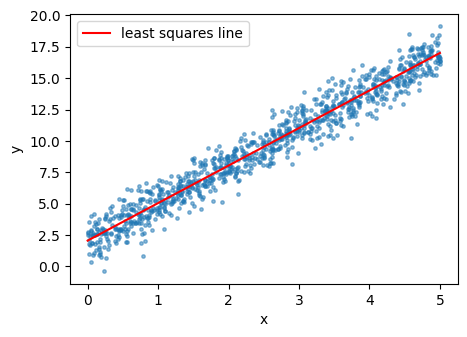

In [ ]:
m = 1000
gen = torch.Generator().manual_seed(0)
x_toy = 5 * torch.rand(m, 1, generator=gen)
y_toy = 3 * x_toy + 2 + torch.randn(m, 1, generator=gen)

# the best possible (w, b), by least squares, to measure how far each run is from it
A = torch.cat([x_toy, torch.ones(m, 1)], dim=1)
w_best, b_best = torch.linalg.lstsq(A, y_toy).solution.flatten().tolist()
J_best = ((w_best * x_toy + b_best - y_toy) ** 2).mean().item()
print(f"least squares: w = {w_best:.3f}, b = {b_best:.3f}, J = {J_best:.4f}")

plt.figure(figsize=(5, 3.5))
plt.scatter(x_toy, y_toy, s=6, alpha=0.5)
plt.plot([0, 5], [b_best, 5 * w_best + b_best], "r", label="least squares line")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

Every run starts from the same point, $w = 0$, $b = 8$, uses the same learning rate $\alpha = 0.01$ and trains for 20 epochs. Only the **batch size** and **momentum** change.

`train_toy` is the PyTorch training loop. After every update it records:
- the loss $J(w, b)$ on **all** 1,000 points (to compare runs fairly, even when they update on different numbers of examples);
- the values of $w$ and $b$ (to draw the path).

In [ ]:
def full_loss(model):
    with torch.no_grad():
        return ((model(x_toy) - y_toy) ** 2).mean().item()

def train_toy(batch_size, lr=0.01, momentum=0.0, epochs=20, seed=0):
    model = nn.Linear(1, 1)
    with torch.no_grad():                              # same starting point for every run
        model.weight.fill_(0.0)
        model.bias.fill_(8.0)
    loss_fn = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    loader = DataLoader(TensorDataset(x_toy, y_toy), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    hist = {"loss": [full_loss(model)], "w": [0.0], "b": [8.0], "epoch_loss": [full_loss(model)], "time": 0.0}
    for epoch in range(epochs):
        for x_t, y_t in loader:
            start = time.perf_counter()
            loss = loss_fn(model(x_t), y_t)            # forward pass and loss on the mini-batch
            optimizer.zero_grad()
            loss.backward()                            # backpropagation
            optimizer.step()                           # update w and b
            hist["time"] += time.perf_counter() - start
            hist["loss"].append(full_loss(model))      # record (not part of training)
            hist["w"].append(model.weight.item()); hist["b"].append(model.bias.item())
        hist["epoch_loss"].append(full_loss(model))
        if (epoch + 1) % 5 == 0:
            print(f"epoch {epoch + 1:2d} | J = {hist['epoch_loss'][-1]:.4f} | w = {model.weight.item():.3f}, b = {model.bias.item():.3f}")
    print(f"updates: {len(hist['loss']) - 1} | training time: {hist['time']:.2f} s")
    return hist

## 2 · Three ways to train

### 2.1 SGD with one example per update
`batch_size=1`: each update uses the gradient of **one** randomly chosen example. One epoch = 1,000 updates.

In [ ]:
hist_sgd = train_toy(batch_size=1)

epoch  5 | J = 0.9849 | w = 3.022, b = 2.163
epoch 10 | J = 0.9812 | w = 3.055, b = 2.048
epoch 15 | J = 1.0084 | w = 2.887, b = 2.127
epoch 20 | J = 0.9500 | w = 2.972, b = 2.112
updates: 20000 | training time: 8.39 s


The loss gets close to its minimum ($J \approx 1.05$, the noise level) within the first epoch, but then it **does not settle**: each update follows a single example, so $w$ and $b$ keep jumping around the minimum.

### 2.2 Mini-batch SGD
`batch_size=32`: each update uses the average gradient of 32 examples. One epoch = 32 updates (the last mini-batch has 8 examples).

In [ ]:
hist_mb = train_toy(batch_size=32)

epoch  5 | J = 3.1727 | w = 2.041, b = 4.983
epoch 10 | J = 1.4506 | w = 2.593, b = 3.461
epoch 15 | J = 1.0610 | w = 2.787, b = 2.724
epoch 20 | J = 0.9762 | w = 2.906, b = 2.381
updates: 640 | training time: 0.31 s


The updates are much less noisy, and each one is computed for 32 examples at once (vectorized). But with the same $\alpha$ there are 32 times fewer updates per epoch, so after 20 epochs the run is still on its way to the minimum.

### 2.3 Mini-batch SGD with momentum
Same mini-batches, with `momentum=0.9`. PyTorch’s update is
$$\mathbf{v} \leftarrow 0.9\,\mathbf{v} + \nabla J^{\{t\}}, \qquad \theta \leftarrow \theta - \alpha\,\mathbf{v}.$$

In [ ]:
hist_mom = train_toy(batch_size=32, momentum=0.9)

epoch  5 | J = 0.9845 | w = 2.942, b = 2.004
epoch 10 | J = 1.1423 | w = 3.120, b = 2.128
epoch 15 | J = 0.9601 | w = 3.024, b = 2.063
epoch 20 | J = 0.9495 | w = 2.997, b = 2.051
updates: 640 | training time: 0.34 s


## 3 · Comparing the three runs
Three views of the same three runs:
1. the loss after each **epoch** (above its minimum $J_{\text{best}}$, on a log scale);
2. the loss after each **update**;
3. the **path** of $(w, b)$ on the contours of $J$.

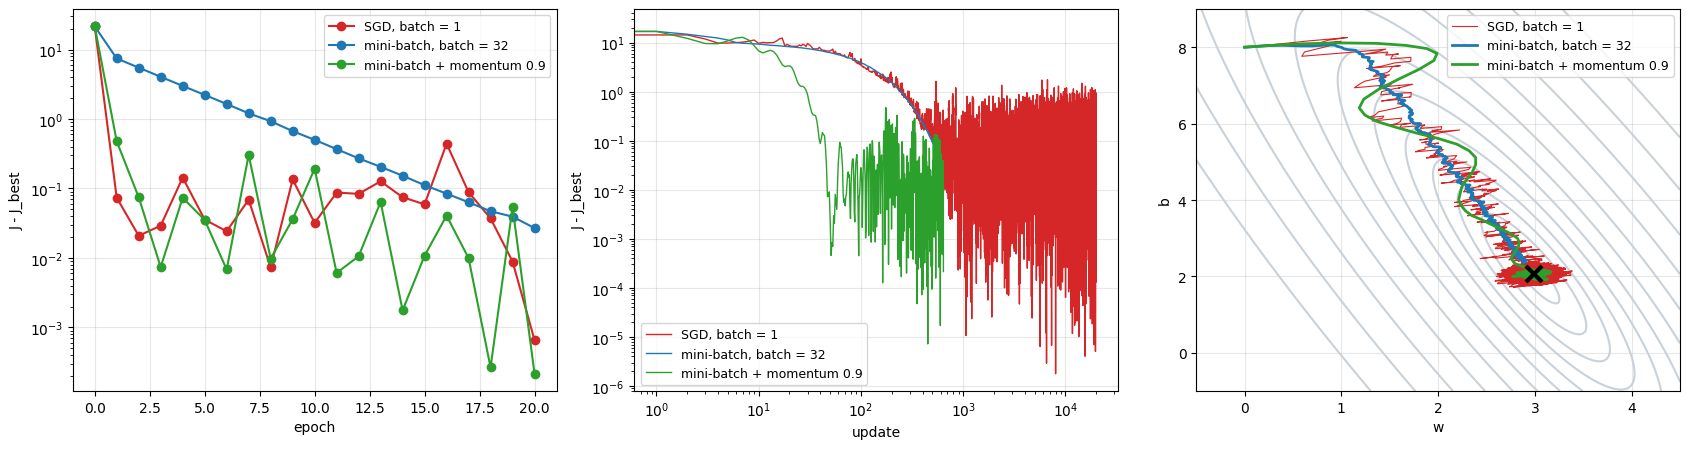

SGD, batch = 1               updates:  20000 | time: 8.39 s | final J - J_best: 0.0007
mini-batch, batch = 32       updates:    640 | time: 0.31 s | final J - J_best: 0.0269
mini-batch + momentum 0.9    updates:    640 | time: 0.34 s | final J - J_best: 0.0002


In [ ]:
runs = {"SGD, batch = 1": hist_sgd, "mini-batch, batch = 32": hist_mb, "mini-batch + momentum 0.9": hist_mom}
colors = ["tab:red", "tab:blue", "tab:green"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for (label, h), c in zip(runs.items(), colors):
    ax[0].plot(np.array(h["epoch_loss"]) - J_best + 1e-6, "o-", color=c, label=label)
    ax[1].plot(np.array(h["loss"]) - J_best + 1e-6, color=c, lw=1, label=label)
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("J - J_best")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("update"); ax[1].set_ylabel("J - J_best")

W, B = torch.meshgrid(torch.linspace(-0.5, 4.5, 200), torch.linspace(-1, 9, 200), indexing="xy")
# J(w, b) on the grid, from the averages of x^2, x, xy, y, y^2 (expand the square)
Ex2, Ex, Exy, Ey, Ey2 = [t.mean().item() for t in (x_toy ** 2, x_toy, x_toy * y_toy, y_toy, y_toy ** 2)]
Jgrid = W ** 2 * Ex2 + 2 * W * B * Ex + B ** 2 - 2 * W * Exy - 2 * B * Ey + Ey2
ax[2].contour(W, B, Jgrid, levels=np.geomspace(1.1, 60, 12), colors="#C9D1D9")
for (label, h), c in zip(runs.items(), colors):
    ax[2].plot(h["w"], h["b"], color=c, lw=0.8 if "= 1" in label else 2, label=label)
ax[2].plot(w_best, b_best, "kx", ms=12, mew=3)
ax[2].set_xlabel("w"); ax[2].set_ylabel("b")
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=9)
plt.tight_layout(); plt.show()

for label, h in runs.items():
    print(f"{label:28s} updates: {len(h['loss']) - 1:6d} | time: {h['time']:.2f} s | final J - J_best: {h['epoch_loss'][-1] - J_best:.4f}")

**What the figure shows**
- **SGD, batch = 1** (red): the most updates per epoch, so the fastest progress per epoch at first. Its path is a cloud of jumps: it reaches the minimum region quickly and then wanders around it. It also takes the most time: 1,000 small updates per epoch, one Python loop iteration each.
- **Mini-batch, batch = 32** (blue): a smooth path, with few updates per epoch. The contours are long, narrow ellipses (a **ravine**: $w$ and $b$ are strongly correlated because $x$ is not centered), and with $\alpha = 0.01$ the run moves slowly along the long direction.
- **Mini-batch + momentum** (green): the same number of updates as blue, but the velocity accumulates the steps along the ravine, so it reaches the minimum much sooner.

The run with batch = 1 would need a **decaying** learning rate to settle, and the run with batch = 32 a larger one or momentum: the batch size, the learning rate and momentum have to be chosen together. The exercises explore this on real data.

## 4 · Tools for the exercises: MNIST

### 4.1 The data
MNIST: 28 × 28 grayscale images of handwritten digits, 10 classes. We keep 54,000 images for training, 6,000 for validation, and the 10,000 test images for the very end. Each image is flattened to a row of 784 values and normalized with the mean and standard deviation of the training pixels. The tensors are prepared once, so the `DataLoader` is fast.

train (54000, 784) | val (6000, 784) | test (10000, 784)


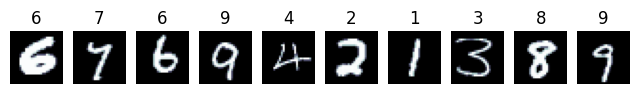

In [ ]:
train_full = datasets.MNIST(root="data", train=True, download=True)
test_full = datasets.MNIST(root="data", train=False, download=True)

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(42))
pixels = train_full.data[perm[:54000]].float() / 255
mean, std = pixels.mean(), pixels.std()                  # training statistics only

def prep(images):
    return ((images.float() / 255 - mean) / std).reshape(len(images), -1)   # (m, 784)

X_all, y_all = prep(train_full.data), train_full.targets
X_train, y_train = X_all[perm[:54000]], y_all[perm[:54000]]
X_val, y_val = X_all[perm[54000:]], y_all[perm[54000:]]
X_test, y_test = prep(test_full.data), test_full.targets
print("train", tuple(X_train.shape), "| val", tuple(X_val.shape), "| test", tuple(X_test.shape))

plt.figure(figsize=(8, 2.4))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="bone"); plt.title(int(y_train[i])); plt.axis("off")
plt.show()

def make_loader(batch_size=64, n_train=None, seed=0):
    # mini-batches of the first n_train training examples (all of them if n_train is None)
    X, y = (X_train, y_train) if n_train is None else (X_train[:n_train], y_train[:n_train])
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))

### 4.2 The model
A multilayer perceptron 784 → 128 → 100 → 10 with ReLU, returning logits. With `batch_norm=True`, an `nn.BatchNorm1d` layer comes after each hidden linear layer, before the ReLU, and the linear layer has no bias (batch norm’s $\beta$ replaces it). `make_model(seed)` gives the same initial weights for the same seed, so that two runs differ only by what you change.

In [ ]:
class MLP(nn.Module):
    def __init__(self, n_in=784, hidden=(128, 100), n_out=10, batch_norm=False):
        super().__init__()
        layers = []
        for h in hidden:
            layers.append(nn.Linear(n_in, h, bias=not batch_norm))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            n_in = h
        layers.append(nn.Linear(n_in, n_out))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)

def make_model(seed=0, **kwargs):
    torch.manual_seed(seed)
    return MLP(**kwargs).to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(make_model())
print(f"{count_parameters(make_model()):,} parameters | with batch norm: {count_parameters(make_model(batch_norm=True)):,}")

MLP(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=100, bias=True)
    (3): ReLU()
    (4): Linear(in_features=100, out_features=10, bias=True)
  )
)
114,390 parameters | with batch norm: 114,618


### 4.3 Training and evaluation
- `evaluate(model, X, y)` returns the loss and the accuracy (%) on a dataset, in evaluation mode.
- `fit(model, optimizer, loader, epochs, scheduler=None)` trains with mini-batches and returns a history: the loss of every update (`"step_loss"`), and per epoch the training loss, the validation loss and accuracy, the learning rate and the elapsed time. If the loss becomes `nan` or `inf`, the run has **diverged**: `fit` stops and sets `"diverged"` to `True`. A scheduler, if given, is stepped once per epoch.
- `plot_history({label: history, ...})` plots the smoothed loss of every update and the validation accuracy per epoch.

In [ ]:
def evaluate(model, X, y, batch_size=2000):
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction="sum")
    total, correct = 0.0, 0
    with torch.inference_mode():
        for i in range(0, len(X), batch_size):
            xb, yb = X[i:i + batch_size].to(device), y[i:i + batch_size].to(device)
            logits = model(xb)
            total += loss_fn(logits, yb).item()
            correct += (logits.argmax(dim=1) == yb).sum().item()
    return total / len(X), 100 * correct / len(X)

def fit(model, optimizer, loader, epochs, scheduler=None, verbose=True):
    loss_fn = nn.CrossEntropyLoss()
    hist = {"step_loss": [], "train_loss": [], "val_loss": [], "val_acc": [], "lr": [], "time": [], "diverged": False}
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        total, count = 0.0, 0
        for X_t, y_t in loader:
            X_t, y_t = X_t.to(device), y_t.to(device)
            loss = loss_fn(model(X_t), y_t)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            hist["step_loss"].append(loss.item())
            total += loss.item() * len(y_t); count += len(y_t)
            if not math.isfinite(loss.item()):
                hist["diverged"] = True
                break
        if scheduler is not None:
            scheduler.step()
        val_loss, val_acc = evaluate(model, X_val, y_val)
        hist["train_loss"].append(total / count); hist["val_loss"].append(val_loss); hist["val_acc"].append(val_acc)
        hist["time"].append(time.perf_counter() - start)
        if verbose:
            print(f"epoch {epoch + 1:2d} | lr {hist['lr'][-1]:.2e} | train loss {total / count:.4f} | "
                  f"val loss {val_loss:.4f} | val acc {val_acc:.2f}% | {hist['time'][-1]:.1f} s")
        if hist["diverged"]:
            print("diverged (loss is nan or inf): stopping")
            break
    return hist

def smooth(values, beta=0.98):
    # exponentially weighted average with bias correction (Lecture 4)
    v, out = 0.0, []
    for t, x in enumerate(values, 1):
        x = x if math.isfinite(x) else 10.0
        v = beta * v + (1 - beta) * x
        out.append(v / (1 - beta ** t))
    return out

def plot_history(hists, title="", ylim=(0, 2.5)):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for label, h in hists.items():
        ax[0].plot(smooth(h["step_loss"]), label=label + (" (diverged)" if h["diverged"] else ""))
        ax[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], "o-", label=label)
    ax[0].set_ylim(*ylim); ax[0].set_xlabel("update"); ax[0].set_ylabel("training loss (smoothed)")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy (%)")
    for a in ax:
        a.grid(alpha=0.3); a.legend(fontsize=9)
    fig.suptitle(title); plt.show()

### 4.4 Check that everything works
One run: Adam, $\alpha = 10^{-3}$, mini-batches of 64, 2 epochs on 10,000 training examples.

epoch  1 | lr 1.00e-03 | train loss 0.5883 | val loss 0.3269 | val acc 90.13% | 0.3 s
epoch  2 | lr 1.00e-03 | train loss 0.2570 | val loss 0.2603 | val acc 92.10% | 0.7 s
epoch  3 | lr 1.00e-03 | train loss 0.1828 | val loss 0.2301 | val acc 93.05% | 1.0 s


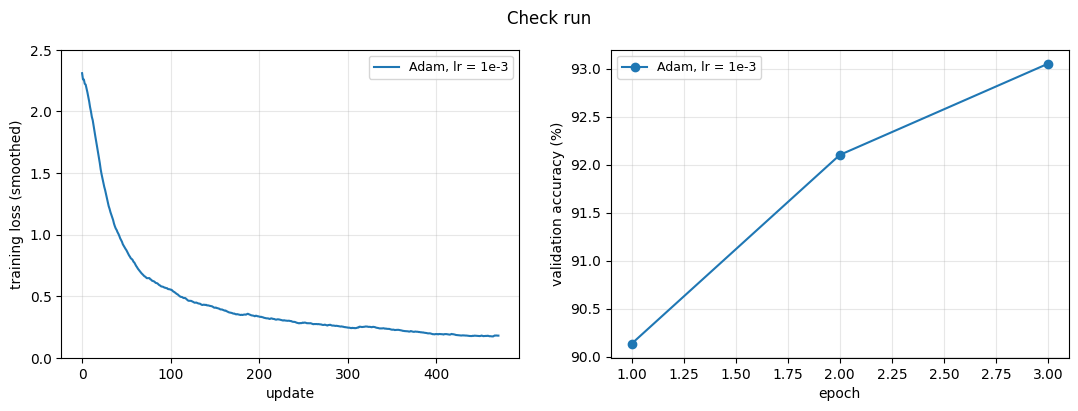

In [ ]:
model = make_model(seed=0)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=10_000), epochs=3)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

---
## ★ Exercises (to submit)

**Rules for all exercises**
- Train on the first **10,000** training examples (`make_loader(..., n_train=10_000)`) for **5 epochs**, unless the exercise says otherwise.
- Create every model with `make_model(seed=0)` (add `batch_norm=True` when asked), so that all runs start from the same weights.
- Use `fit`, `evaluate` and `plot_history` from Part 4. Choose everything on the **validation** set; use the test set only in Exercise 8.
- A run that diverges is a result too: report it.


### Exercise 1 · The learning rate of SGD
1. Train with `optim.SGD` (no momentum), batch size 64, for each $\alpha \in \{1, 0.3, 0.1, 0.03, 0.01, 0.001\}$.
2. Plot the six runs on one figure with `plot_history`.
3. Print the best validation accuracy of each run.

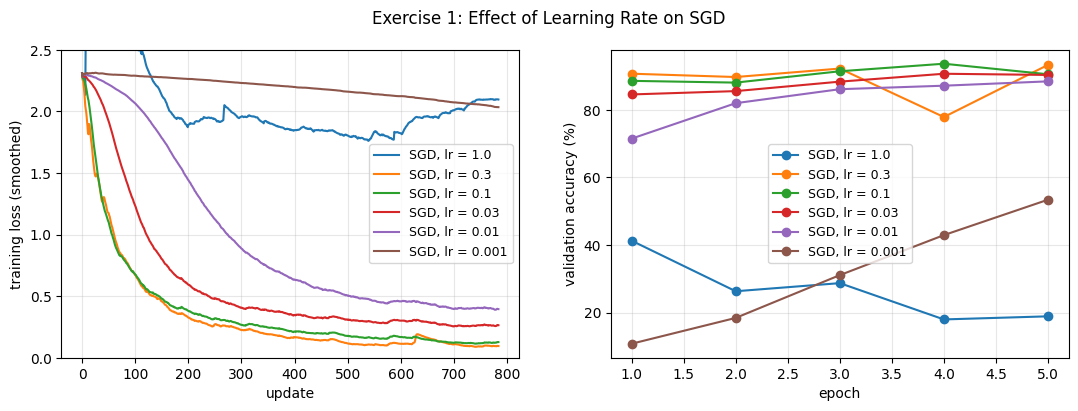

Learning Rate   | Best Val Acc | Final Train Loss |     Status
------------------------------------------------------------
          1.000 |       41.28% |           2.0679 |  Converged
          0.300 |       93.27% |           0.1064 |  Converged
          0.100 |       93.62% |           0.1164 |  Converged
          0.030 |       90.65% |           0.2572 |  Converged
          0.010 |       88.40% |           0.3938 |  Converged
          0.001 |       53.40% |           2.0486 |  Converged


In [ ]:
# Exercise 1
# exercise 1: the learning rate of SGD
lrs_ex1 = [1.0, 0.3, 0.1, 0.03, 0.01, 0.001]
hists_ex1 = {}

for lr in lrs_ex1:
    m = make_model(seed=0)
    opt = optim.SGD(m.parameters(), lr=lr)
    label = f"SGD, lr = {lr}"
    hists_ex1[label] = fit(m, opt, make_loader(batch_size=64, n_train=10_000), epochs=5, verbose=False)

# plot all six runs
plot_history(hists_ex1, "Exercise 1: Effect of Learning Rate on SGD", ylim=(0, 2.5))

# print the best validation accuracy of each run
print(f"{'Learning Rate':15s} | {'Best Val Acc':>12s} | {'Final Train Loss':>16s} | {'Status':>10s}")
print("-" * 60)
for lr in lrs_ex1:
    label = f"SGD, lr = {lr}"
    h = hists_ex1[label]
    best_acc = max(h["val_acc"]) if h["val_acc"] else 0.0
    final_loss = h["train_loss"][-1] if h["train_loss"] else float('nan')
    status = "Diverged" if h["diverged"] else "Converged"
    print(f"{lr:15.3f} | {best_acc:11.2f}% | {final_loss:16.4f} | {status:>10s}")


**Exercise 1: your observations and explanation.**

The learning rate has a clear sweet spot. With batch size 64 and 5 epochs (about 785 updates), $\alpha = 0.3$ and $\alpha = 0.1$ are the best, with best validation accuracy of 93.27% and 93.62% and a final training loss around 0.11. Going down, the runs get steadily worse: 0.03 gives 90.65%, 0.01 gives 88.40%, and 0.001 only reaches 53.40% with the loss still at 2.05, which is barely below the starting value of about 2.3 (that is $\ln 10$, a random guess over 10 classes). At the other end, $\alpha = 1$ does not learn at all: the loss starts above 2.5, hovers around 2 afterwards, and the validation accuracy falls from 41% to under 20%. The table prints "Converged" for this run, but that only means the loss never became nan, not that training worked.

The explanation is the usual two-sided one. A step that is too small moves the weights only a little at each update, so after 785 updates the model has hardly left the initial plateau (the 0.001 curve is a slow, almost straight line and its accuracy is still going up, so it just needs many more epochs). A step that is too large overshoots the minimum and lands at a point with a higher loss, so the loss bounces instead of going down. The best value is the largest one that is still stable. Note also that the 0.1 and 0.3 curves are almost on top of each other, and their validation accuracy moves by several points from one epoch to the next (0.3 drops to about 78% at epoch 4 and comes back at epoch 5), so a difference of a few tenths between them is noise, and "best validation accuracy" is a maximum over noisy epochs.

### Exercise 2 · Batch size: one example, mini-batches, the full set
1. Train with `optim.SGD`, $\alpha = 0.01$, for **3 epochs**, with batch sizes 1, 32, 256 and 10,000 (10,000 = batch gradient descent on this training set).
2. For each run, print the number of updates per epoch, the time per epoch and the best validation accuracy.
3. Plot the four runs.
4. Repeat steps 1–3 with $\alpha = 0.1$.


Learning rate = 0.01

Batch size = 1
Updates per epoch: 10000
Time per epoch: [13.88, 13.74, 13.63] seconds
Best validation accuracy: 93.57%
Status: Completed

Batch size = 32
Updates per epoch: 313
Time per epoch: [0.51, 0.49, 0.53] seconds
Best validation accuracy: 88.87%
Status: Completed

Batch size = 256
Updates per epoch: 40
Time per epoch: [0.13, 0.13, 0.12] seconds
Best validation accuracy: 64.63%
Status: Completed

Batch size = 10000
Updates per epoch: 1
Time per epoch: [0.1, 0.08, 0.1] seconds
Best validation accuracy: 9.80%
Status: Completed


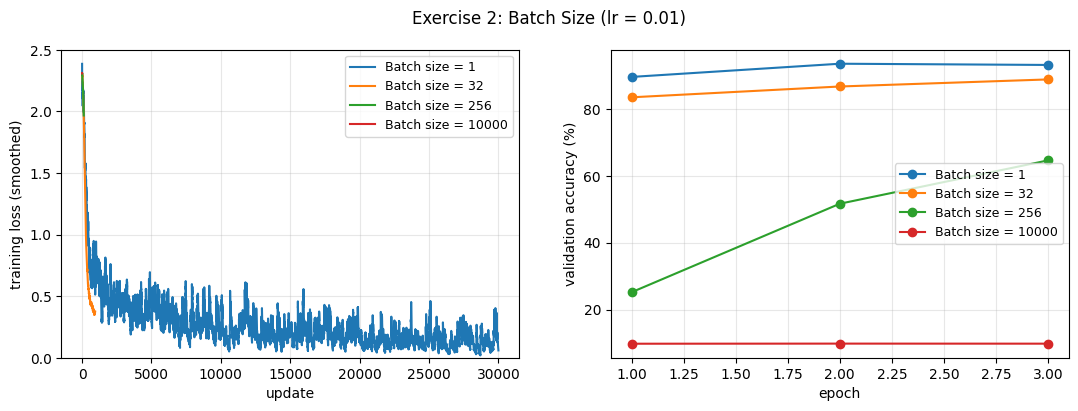


Learning rate = 0.1
diverged (loss is nan or inf): stopping

Batch size = 1
Updates per epoch: 10000
Time per epoch: [13.74, 12.7] seconds
Best validation accuracy: 9.95%
Status: Diverged

Batch size = 32
Updates per epoch: 313
Time per epoch: [0.51, 0.49, 0.5] seconds
Best validation accuracy: 93.57%
Status: Completed

Batch size = 256
Updates per epoch: 40
Time per epoch: [0.12, 0.13, 0.13] seconds
Best validation accuracy: 74.63%
Status: Completed

Batch size = 10000
Updates per epoch: 1
Time per epoch: [0.08, 0.35, 0.09] seconds
Best validation accuracy: 17.55%
Status: Completed


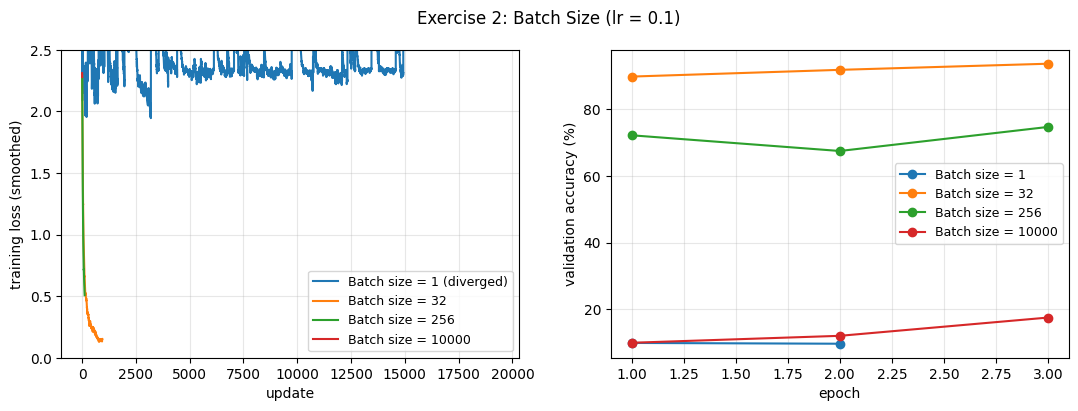

In [ ]:
# Exercise 2

# Exercise 2: Batch size

batch_sizes_ex2 = [1, 32, 256, 10_000]
lrs_ex2 = [0.01, 0.1]

hists_ex2 = {}

for lr in lrs_ex2:

    hists_ex2[lr] = {}

    print(f"\n{'='*75}")
    print(f"Learning rate = {lr}")
    print(f"{'='*75}")

    for bs in batch_sizes_ex2:

        m = make_model(seed=0)
        opt = optim.SGD(m.parameters(), lr=lr)

        label = f"Batch size = {bs}"

        h = fit(
            m,
            opt,
            make_loader(batch_size=bs, n_train=10_000),
            epochs=3,
            verbose=False
        )

        hists_ex2[lr][label] = h

        # Number of updates per epoch
        updates = math.ceil(10_000 / bs)

        # Time taken by each epoch
        epoch_times = [
            h["time"][0]
        ] + [
            h["time"][i] - h["time"][i - 1]
            for i in range(1, len(h["time"]))
        ]

        best_acc = max(h["val_acc"]) if h["val_acc"] else 0.0

        print(f"\n{label}")
        print(f"Updates per epoch: {updates}")
        print(f"Time per epoch: {[round(t, 2) for t in epoch_times]} seconds")
        print(f"Best validation accuracy: {best_acc:.2f}%")
        print(f"Status: {'Diverged' if h['diverged'] else 'Completed'}")

    # Plot the four batch sizes for this learning rate
    plot_history(
        hists_ex2[lr],
        f"Exercise 2: Batch Size (lr = {lr})"
    )


**Exercise 2: your observations and explanation.**

With $\alpha = 0.01$, the ranking after 3 epochs follows the number of updates. Batch 1 (10,000 updates per epoch) reaches 93.57%, batch 32 (313 per epoch) 88.87%, batch 256 (40 per epoch) 64.63%, and batch 10,000 (one update per epoch, so only 3 in total) is still at chance level, 9.80%. Same learning rate and same number of epochs, so a bigger batch simply means fewer steps, and the cleaner gradient does not make up for it. The noise of small batches is visible in the loss plot: batch 1 is very jagged, with the smoothed loss jumping between 0.1 and 0.5 even after 30,000 updates, while batch 32 is smooth.

The time gives the other half of the story. An epoch takes about 13.7 s with batch 1, 0.5 s with batch 32, 0.13 s with batch 256 and 0.1 s with the full batch. One update costs about the same for batch 1 and batch 32 (1 to 2 ms), so the time is mostly overhead of the Python loop and not arithmetic, and a batch of 32 processes 32 times more examples for the same price. In wall-clock time, batch 32 got 88.9% in about 1.5 s in total, while batch 1 needed about 41 s to get 93.6%. This is why mini-batches are the practical middle: much cheaper than single examples, and many more updates than the full batch.

With $\alpha = 0.1$ the picture changes. Batch 1 diverges (the loss stays near 2.3 and then becomes nan in the second epoch, accuracy 9.95%): a step of 0.1 on the gradient of a single example is too violent, and nothing averages the noise. Batch 32 now reaches 93.57%, the same accuracy that batch 1 got with $\alpha = 0.01$, with about 32 times fewer updates. Batch 256 improves to 74.63% and the full batch to 17.55%, but both still have too few updates. So the best learning rate depends on the batch size: small batches have noisy gradients and need a smaller $\alpha$, larger batches have cleaner gradients and can (and need to) use a bigger one.

### Exercise 3 · Momentum
1. With batch size 64 and $\alpha = 0.01$, train: `optim.SGD(p, lr)`, `optim.SGD(p, lr, momentum=0.9)` and `optim.SGD(p, lr, momentum=0.9, nesterov=True)`.
2. Train `optim.SGD(p, lr=0.001, momentum=0.9)` and compare it with plain SGD at $\alpha = 0.01$.
3. Train `optim.SGD(p, lr, momentum=0.99)` with $\alpha = 0.01$.
4. Plot all the runs on one figure.

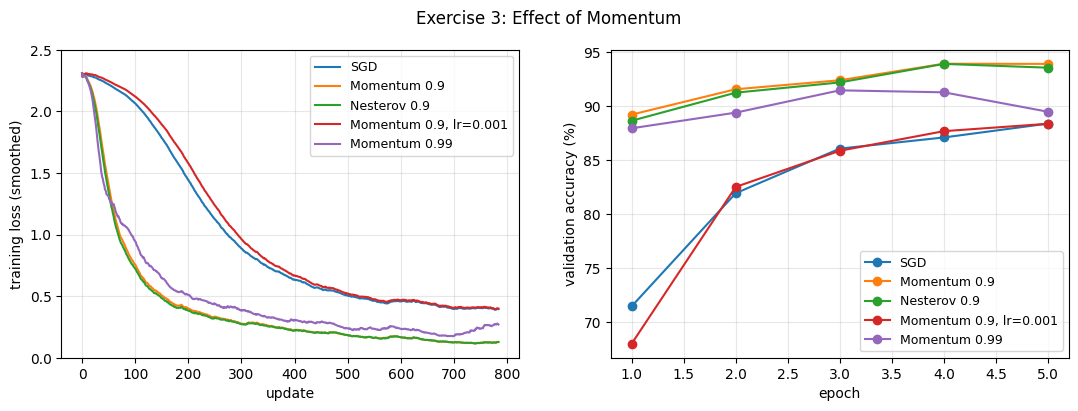

In [ ]:
# Exercise 3

# Exercise 3: Momentum

hists_ex3 = {}

lr = 0.01
batch_size = 64

# 1. Plain SGD
m = make_model(seed=0)
opt = optim.SGD(m.parameters(), lr=lr)
hists_ex3["SGD"] = fit(
    m, opt,
    make_loader(batch_size=batch_size, n_train=10_000),
    epochs=5,
    verbose=False
)

# 2. SGD with momentum = 0.9
m = make_model(seed=0)
opt = optim.SGD(m.parameters(), lr=lr, momentum=0.9)
hists_ex3["Momentum 0.9"] = fit(
    m, opt,
    make_loader(batch_size=batch_size, n_train=10_000),
    epochs=5,
    verbose=False
)

# 3. SGD with Nesterov momentum = 0.9
m = make_model(seed=0)
opt = optim.SGD(m.parameters(), lr=lr, momentum=0.9, nesterov=True)
hists_ex3["Nesterov 0.9"] = fit(
    m, opt,
    make_loader(batch_size=batch_size, n_train=10_000),
    epochs=5,
    verbose=False
)

# 4. Momentum = 0.9 with learning rate = 0.001
m = make_model(seed=0)
opt = optim.SGD(m.parameters(), lr=0.001, momentum=0.9)
hists_ex3["Momentum 0.9, lr=0.001"] = fit(
    m, opt,
    make_loader(batch_size=batch_size, n_train=10_000),
    epochs=5,
    verbose=False
)

# 5. Momentum = 0.99
m = make_model(seed=0)
opt = optim.SGD(m.parameters(), lr=lr, momentum=0.99)
hists_ex3["Momentum 0.99"] = fit(
    m, opt,
    make_loader(batch_size=batch_size, n_train=10_000),
    epochs=5,
    verbose=False
)

# Plot all runs
plot_history(
    hists_ex3,
    "Exercise 3: Effect of Momentum",
    ylim=(0, 2.5)
)


**Exercise 3: your observations and explanation.**

Momentum 0.9 with $\alpha = 0.01$ is clearly better than plain SGD with the same $\alpha$: the training loss goes down much faster (about 0.12 against 0.4 after 5 epochs) and the best validation accuracy is 93.95% against 88.40%. Nesterov gives almost the same curve (about 94% as well), so on this problem I cannot see a difference between classical and Nesterov momentum.

The most informative run is momentum 0.9 with $\alpha = 0.001$. It ends at 88.38%, which is the same as plain SGD with $\alpha = 0.01$ (88.40%), and the two loss curves almost overlap (the momentum one is a bit slower at the start). This matches the fact that the velocity accumulates gradients, so when the gradient keeps the same direction the step is about $\alpha / (1 - \beta)$, ten times larger for $\beta = 0.9$. In the same way, momentum 0.9 with $\alpha = 0.01$ behaves like plain SGD with $\alpha = 0.1$ (93.62% in Exercise 1). So on MNIST a good part of the gain from momentum looks like a bigger effective step, plus some smoothing of the noisy mini-batch gradients.

Momentum 0.99 with $\alpha = 0.01$ is worse than 0.9. The effective step is $0.01 / 0.01 = 1$, which was already too large for plain SGD in Exercise 1. The loss falls quickly at first, but then stalls around 0.25 to 0.3 and is bumpy, and the validation accuracy peaks at about 91.5% at epoch 3 and goes back down to about 89.4%. With $\beta = 0.99$ the velocity remembers around 100 past gradients, so it reacts slowly when the direction changes and overshoots, like a heavy ball rolling past the bottom of the valley. The conclusion is that $\beta = 0.9$ is a good default, and that momentum and $\alpha$ have to be chosen together.

### Exercise 4 · Optimizers and their learning rates
1. For each optimizer below, train with $\alpha \in \{10^{-1}, 10^{-2}, 10^{-3}, 10^{-4}\}$, batch size 64:
   `optim.SGD`, `optim.SGD(momentum=0.9)`, `optim.Adagrad`, `optim.RMSprop`, `optim.Adam`, `optim.AdamW`.
2. Show a table of the best validation accuracy: one row per optimizer, one column per learning rate.
3. Plot the best run of each optimizer on one figure.

Optimizer       |        0.1 |       0.01 |      0.001 |     0.0001
-----------------------------------------------------------------
SGD             |     93.62% |     88.40% |     53.40% |      9.88%
SGD Momentum    |     92.75% |     93.95% |     88.38% |     52.55%
Adagrad         |     92.35% |     93.93% |     89.15% |     67.98%
RMSprop         |     22.07% |     90.07% |     94.18% |     89.92%
Adam            |     27.10% |     92.45% |     94.17% |     90.03%
AdamW           |     36.60% |     92.78% |     94.02% |     90.05%
Best SGD: learning rate = 0.1, accuracy = 93.62%
Best SGD Momentum: learning rate = 0.01, accuracy = 93.95%
Best Adagrad: learning rate = 0.01, accuracy = 93.93%
Best RMSprop: learning rate = 0.001, accuracy = 94.18%
Best Adam: learning rate = 0.001, accuracy = 94.17%
Best AdamW: learning rate = 0.001, accuracy = 94.02%


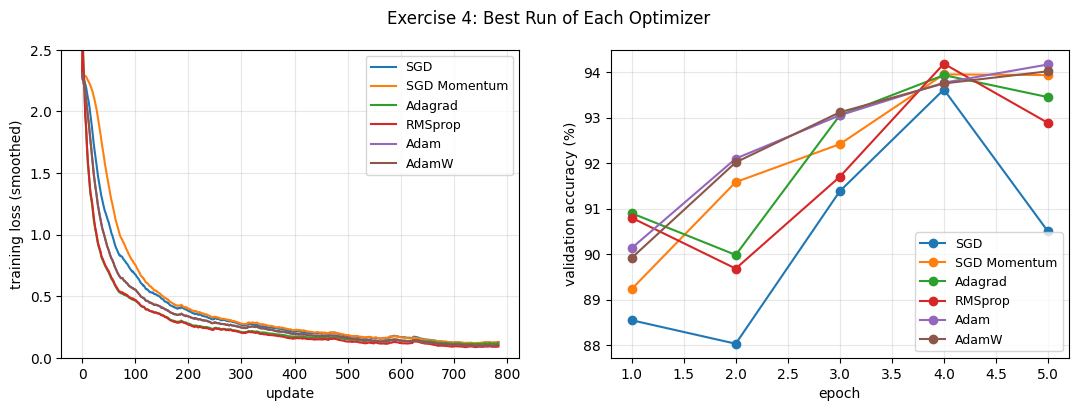

In [ ]:
# Exercise 4

# Exercise 4: Optimizers and their learning rates

lrs_ex4 = [0.1, 0.01, 0.001, 0.0001]

optimizer_names = [
    "SGD",
    "SGD Momentum",
    "Adagrad",
    "RMSprop",
    "Adam",
    "AdamW"
]

hists_ex4 = {}
best_hists_ex4 = {}

for name in optimizer_names:

    hists_ex4[name] = {}

    for lr in lrs_ex4:

        m = make_model(seed=0)

        if name == "SGD":
            opt = optim.SGD(m.parameters(), lr=lr)

        elif name == "SGD Momentum":
            opt = optim.SGD(m.parameters(), lr=lr, momentum=0.9)

        elif name == "Adagrad":
            opt = optim.Adagrad(m.parameters(), lr=lr)

        elif name == "RMSprop":
            opt = optim.RMSprop(m.parameters(), lr=lr)

        elif name == "Adam":
            opt = optim.Adam(m.parameters(), lr=lr)

        elif name == "AdamW":
            opt = optim.AdamW(m.parameters(), lr=lr)

        h = fit(
            m,
            opt,
            make_loader(batch_size=64, n_train=10_000),
            epochs=5,
            verbose=False
        )

        hists_ex4[name][lr] = h

# Print the table of best validation accuracies
print(f"{'Optimizer':15s}", end="")

for lr in lrs_ex4:
    print(f" | {lr:>10g}", end="")

print()
print("-" * 65)

for name in optimizer_names:
    print(f"{name:15s}", end="")

    for lr in lrs_ex4:
        h = hists_ex4[name][lr]
        best_acc = max(h["val_acc"]) if h["val_acc"] else 0.0
        print(f" | {best_acc:9.2f}%", end="")

    print()

# Find the best run of each optimizer
for name in optimizer_names:

    best_lr = max(
        lrs_ex4,
        key=lambda lr: max(hists_ex4[name][lr]["val_acc"])
        if hists_ex4[name][lr]["val_acc"] else 0.0
    )

    best_hists_ex4[name] = hists_ex4[name][best_lr]

    print(
        f"Best {name}: learning rate = {best_lr}, "
        f"accuracy = {max(best_hists_ex4[name]['val_acc']):.2f}%"
    )

# Plot the best run of each optimizer
plot_history(
    best_hists_ex4,
    "Exercise 4: Best Run of Each Optimizer",
    ylim=(0, 2.5)
)


**Exercise 4: your observations and explanation.**

At its best learning rate, every optimizer ends in a narrow band: SGD 93.62% ($\alpha = 0.1$), SGD with momentum 93.95% (0.01), Adagrad 93.93% (0.01), RMSprop 94.18% (0.001), Adam 94.17% (0.001) and AdamW 94.02% (0.001). The spread is about 0.6 points, which is smaller than the epoch-to-epoch wobble of the validation curves, so I would not rank them. What the table does show clearly is that each optimizer has its own good learning rate: around 0.1 for plain SGD, 0.01 for SGD with momentum and Adagrad, and 0.001 for RMSprop, Adam and AdamW. Taking the rate of one optimizer and using it on another is a mistake: Adam with 0.1 gives 27.10% (RMSprop 22.07%, AdamW 36.60%), while 0.1 is the best rate for plain SGD.

The reason is how the step is built. SGD moves by $\alpha$ times the gradient, and the gradients on MNIST are small, so it needs a large $\alpha$. RMSprop and Adam divide the gradient by a running estimate of its size, so every weight moves by roughly $\alpha$ at each update whatever the size of its gradient. With $\alpha = 0.1$ that is a huge jump for all the weights at once, and 0.001 is the natural scale. The same normalization explains the other end of the table: with $\alpha = 10^{-4}$ the adaptive methods still reach about 90%, while SGD is at 9.88%, SGD with momentum at 52.55% and Adagrad at 67.98%. So RMSprop, Adam and AdamW are the least sensitive to the learning rate (about 90% or better from 0.01 to 0.0001) and plain SGD is the most sensitive. Adagrad accumulates the squared gradients, so its effective step keeps shrinking, which is why it likes a larger $\alpha$ and is fine even with 0.1 (92.35%). Adam and AdamW are almost identical here: AdamW only differs by the decoupled weight decay, and 5 epochs on 10,000 images is too short for that to matter.

In the plot of the best runs, the adaptive methods go down fastest at the beginning and SGD with momentum is the slowest to start, but after about 600 updates the training losses are all close to 0.1.

### Exercise 5 · Learning rate schedules
1. With `optim.SGD(p, lr=0.05, momentum=0.9)` and batch size 64, train for **10 epochs** with:
   - a constant learning rate;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)`;
   - `optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.7)`;
   - `optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)`;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.1)` (decays too early).
2. Plot the learning rate of each run per epoch (from `history["lr"]`), with a log scale on the y-axis.
3. Plot the five runs with `plot_history(..., ylim=(0, 0.8))`.

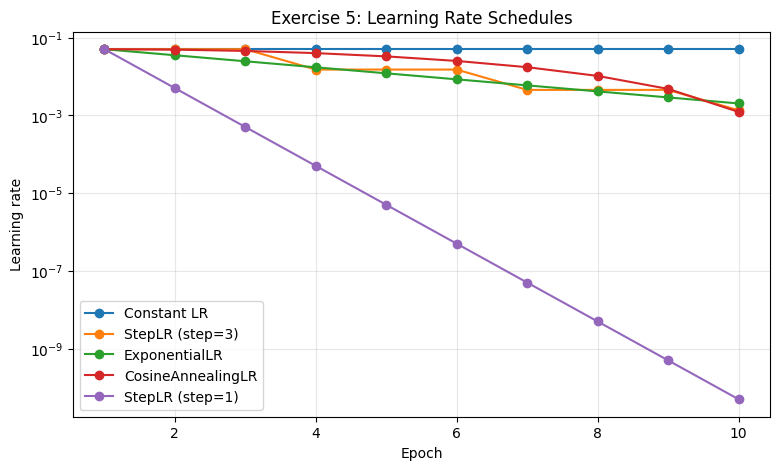

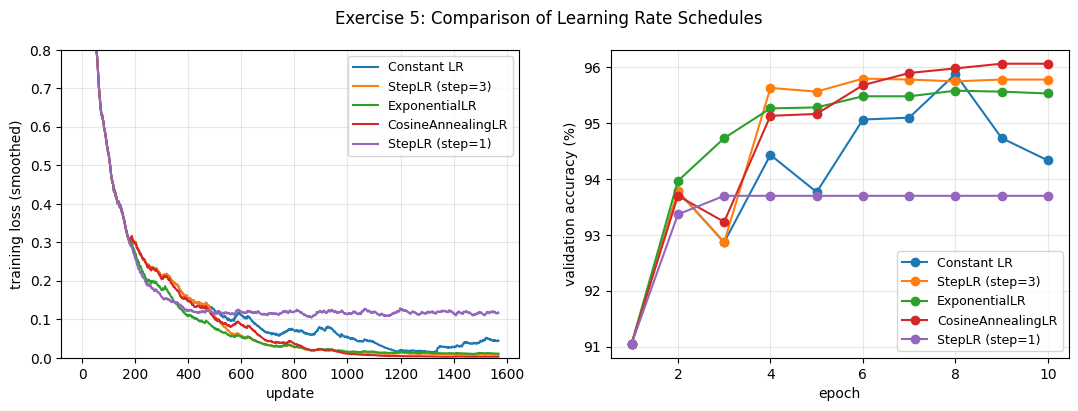

In [ ]:
# Exercise 5

# Exercise 5: Learning rate schedules

hists_ex5 = {}

schedule_names = [
    "Constant LR",
    "StepLR (step=3)",
    "ExponentialLR",
    "CosineAnnealingLR",
    "StepLR (step=1)"
]

for name in schedule_names:

    m = make_model(seed=0)
    opt = optim.SGD(m.parameters(), lr=0.05, momentum=0.9)

    if name == "Constant LR":
        scheduler = None

    elif name == "StepLR (step=3)":
        scheduler = optim.lr_scheduler.StepLR(
            opt, step_size=3, gamma=0.3
        )

    elif name == "ExponentialLR":
        scheduler = optim.lr_scheduler.ExponentialLR(
            opt, gamma=0.7
        )

    elif name == "CosineAnnealingLR":
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
            opt, T_max=10
        )

    elif name == "StepLR (step=1)":
        scheduler = optim.lr_scheduler.StepLR(
            opt, step_size=1, gamma=0.1
        )

    hists_ex5[name] = fit(
        m,
        opt,
        make_loader(batch_size=64, n_train=10_000),
        epochs=10,
        scheduler=scheduler,
        verbose=False
    )

# Plot the learning rate per epoch
plt.figure(figsize=(9, 5))

for name, h in hists_ex5.items():
    plt.plot(
        range(1, len(h["lr"]) + 1),
        h["lr"],
        marker="o",
        label=name
    )

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.title("Exercise 5: Learning Rate Schedules")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Plot training loss and validation accuracy
plot_history(
    hists_ex5,
    "Exercise 5: Comparison of Learning Rate Schedules",
    ylim=(0, 0.8)
)


**Exercise 5: your observations and explanation.**

All the runs start from the same rate, 0.05, and the first epoch is identical (91.05%), but the end of training is very different. After 10 epochs cosine annealing is the best (about 96.1%), then StepLR with step 3 (about 95.8%) and exponential decay (about 95.5%). The constant rate reaches 95.9% at epoch 8 but then falls to 94.3% at epoch 10, and its training loss stays around 0.04 with small bumps, while the three decaying runs go down to about 0.01 and stay smooth. With only one run per schedule, I would not claim that cosine is really better than the other two, but the gap between them and the constant rate is clear.

The explanation is that near the minimum the noise of the mini-batch gradients keeps pushing the weights around, and a large step makes this worse. When $\alpha$ decreases, the weights can settle. A large rate at the beginning is still useful, because it makes fast progress, and a slow decay (cosine, exponential, step 3) keeps both advantages.

Decaying too early is the failure case. StepLR with step 1 and $\gamma = 0.1$ divides the rate by 10 at every epoch: 0.005 at epoch 2, 0.0005 at epoch 3, and about $5 \cdot 10^{-11}$ at epoch 10. From epoch 3 the weights are almost frozen: the validation accuracy is a flat line at 93.70% and the training loss stays around 0.11 to 0.12, while the other runs go below 0.02. This is different from a rate that is too small from the start (Exercise 1), where the run is only slow. Here the run has stopped. So the schedule has to be chosen with the number of epochs in mind: the rate should become small near the end of training, not at the beginning.

### Exercise 6 · Batch normalization
1. For $\alpha \in \{1, 10^{-1}, 10^{-2}, 10^{-3}\}$, train `optim.SGD(p, lr, momentum=0.9)` with batch size 64, once **without** and once **with** batch norm (`make_model(seed=0, batch_norm=True)`).
2. Show a table of the best validation accuracy: rows = learning rates, columns = without / with batch norm.
3. Plot the eight runs.
4. Take your batch-norm model trained with $\alpha = 10^{-2}$. Evaluate it on the validation set in `model.eval()` mode (as `evaluate` does) and in `model.train()` mode with mini-batches of 8 examples, and compare the two accuracies.

diverged (loss is nan or inf): stopping
Learning Rate   |   Without BN |      With BN
------------------------------------------------
          1.000 |        9.72% |       89.70%
          0.100 |       92.75% |       95.15%
          0.010 |       93.95% |       95.38%
          0.001 |       88.38% |       92.75%


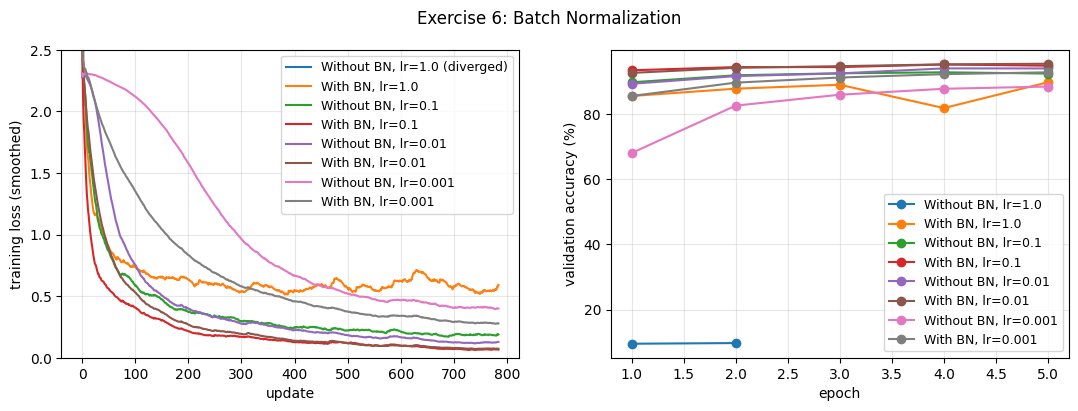


Comparison of batch normalization modes
Accuracy in eval() mode:  95.38%
Accuracy in train() mode: 85.15%


In [ ]:
# Exercise 6

# Exercise 6: Batch normalization

lrs_ex6 = [1.0, 0.1, 0.01, 0.001]

hists_ex6 = {}
bn_model_ex6 = None

for lr in lrs_ex6:

    # Model without batch normalization
    m = make_model(seed=0)
    opt = optim.SGD(m.parameters(), lr=lr, momentum=0.9)

    hists_ex6[f"Without BN, lr={lr}"] = fit(
        m,
        opt,
        make_loader(batch_size=64, n_train=10_000),
        epochs=5,
        verbose=False
    )

    # Model with batch normalization
    m_bn = make_model(seed=0, batch_norm=True)
    opt_bn = optim.SGD(m_bn.parameters(), lr=lr, momentum=0.9)

    h_bn = fit(
        m_bn,
        opt_bn,
        make_loader(batch_size=64, n_train=10_000),
        epochs=5,
        verbose=False
    )

    hists_ex6[f"With BN, lr={lr}"] = h_bn

    # Save the BN model trained with lr = 0.01
    if lr == 0.01:
        bn_model_ex6 = m_bn

# Print the best validation accuracy table
print(f"{'Learning Rate':15s} | {'Without BN':>12s} | {'With BN':>12s}")
print("-" * 48)

for lr in lrs_ex6:

    h_without = hists_ex6[f"Without BN, lr={lr}"]
    h_with = hists_ex6[f"With BN, lr={lr}"]

    acc_without = max(h_without["val_acc"]) if h_without["val_acc"] else 0.0
    acc_with = max(h_with["val_acc"]) if h_with["val_acc"] else 0.0

    print(f"{lr:15.3f} | {acc_without:11.2f}% | {acc_with:11.2f}%")

# Plot all eight runs
plot_history(
    hists_ex6,
    "Exercise 6: Batch Normalization",
    ylim=(0, 2.5)
)

# Compare evaluation mode and training mode
# First: evaluation mode, using the evaluate() function
eval_loss, eval_acc = evaluate(bn_model_ex6, X_val, y_val)

# Second: training mode with mini-batches of 8
bn_model_ex6.train()

correct = 0
total = 0

with torch.inference_mode():

    for i in range(0, len(X_val), 8):

        xb = X_val[i:i + 8].to(device)
        yb = y_val[i:i + 8].to(device)

        logits = bn_model_ex6(xb)
        predictions = logits.argmax(dim=1)

        correct += (predictions == yb).sum().item()
        total += len(yb)

train_mode_acc = 100 * correct / total

print("\nComparison of batch normalization modes")
print(f"Accuracy in eval() mode:  {eval_acc:.2f}%")
print(f"Accuracy in train() mode: {train_mode_acc:.2f}%")


**Exercise 6: your observations and explanation.**

Batch norm helps at all four learning rates: 9.72% to 89.70% at $\alpha = 1$, 92.75% to 95.15% at 0.1, 93.95% to 95.38% at 0.01, and 88.38% to 92.75% at 0.001. The biggest change is at $\alpha = 1$: without batch norm the run diverges (nan), with it the model trains and reaches 89.70%, although it stays noisy (the loss stays around 0.5 to 0.6 and the validation accuracy drops to about 82% at epoch 4). At the small end, with $\alpha = 0.001$, batch norm gains 4.4 points, and the loss goes down from the first updates, while the model without it stays close to its starting loss for the first 100 updates or so. The best accuracy is also higher with batch norm (95.38% against 93.95%), and both 0.1 and 0.01 work well, so the range of usable learning rates is wider.

Batch norm normalizes the input of each ReLU with the mean and variance of the mini-batch, then rescales it with the learned $\gamma$ and $\beta$. This keeps the scale of the activations under control whatever the weights do, so a large step cannot blow up the inputs of the next layer, and the gradients behave better. The loss is easier to optimize, so the network accepts a larger $\alpha$ and also learns faster with a small one.

For the model with batch norm trained with $\alpha = 0.01$, the validation accuracy is 95.38% in `eval()` mode and 85.15% in `train()` mode with mini-batches of 8, a drop of about ten points. In `eval()` mode, batch norm uses the running mean and variance collected during training, which are fixed numbers for all the examples. In `train()` mode it uses the statistics of the 8 images in the batch. 8 examples are too few to estimate the mean and variance of a layer well, these estimates are different from those of the batches of 64 used for training, and the prediction for one image depends on the 7 others. So `model.eval()` is not optional with batch norm, and batch norm works badly with very small batches.

### Exercise 7 · Your best model
1. Using what you learned in Exercises 1–6, choose an optimizer, a learning rate, a batch size, a schedule (or none), and with or without batch norm.
2. Train on the **full** training set (`n_train=None`) for 10 epochs.
3. Report the validation accuracy per epoch, and list your choices with one reason for each.

epoch  1 | lr 1.00e-03 | train loss 0.2743 | val loss 0.1614 | val acc 95.08% | 1.9 s
epoch  2 | lr 1.00e-03 | train loss 0.1180 | val loss 0.1251 | val acc 96.15% | 3.7 s
epoch  3 | lr 1.00e-03 | train loss 0.0840 | val loss 0.0955 | val acc 97.03% | 5.6 s
epoch  4 | lr 1.00e-03 | train loss 0.0620 | val loss 0.0803 | val acc 97.40% | 7.4 s
epoch  5 | lr 1.00e-03 | train loss 0.0510 | val loss 0.0833 | val acc 97.43% | 9.3 s
epoch  6 | lr 1.00e-03 | train loss 0.0412 | val loss 0.0867 | val acc 97.52% | 11.5 s
epoch  7 | lr 1.00e-03 | train loss 0.0351 | val loss 0.0944 | val acc 97.22% | 13.5 s
epoch  8 | lr 1.00e-03 | train loss 0.0310 | val loss 0.1220 | val acc 96.82% | 15.3 s
epoch  9 | lr 1.00e-03 | train loss 0.0274 | val loss 0.0923 | val acc 97.78% | 17.2 s
epoch 10 | lr 1.00e-03 | train loss 0.0229 | val loss 0.1100 | val acc 97.40% | 19.0 s


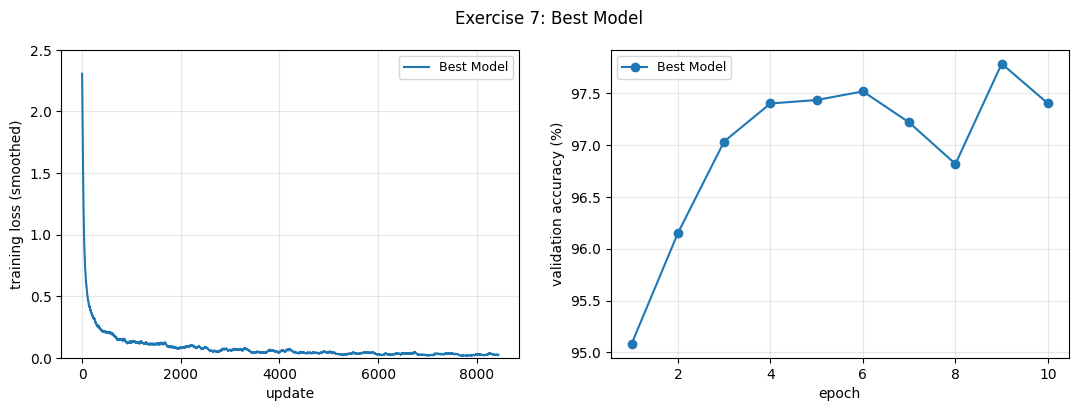


Validation accuracy per epoch:
Epoch 1: 95.08%
Epoch 2: 96.15%
Epoch 3: 97.03%
Epoch 4: 97.40%
Epoch 5: 97.43%
Epoch 6: 97.52%
Epoch 7: 97.22%
Epoch 8: 96.82%
Epoch 9: 97.78%
Epoch 10: 97.40%

Best validation accuracy: 97.78%


In [ ]:
# Exercise 7

# Exercise 7: Your best model

# Choose the configuration
best_optimizer_ex7 = "Adam"
best_lr_ex7 = 0.001
best_batch_size_ex7 = 64
best_batch_norm_ex7 = False

# Create the model
best_model_ex7 = make_model(
    seed=0,
    batch_norm=best_batch_norm_ex7
)

# Choose the optimizer
if best_optimizer_ex7 == "Adam":
    optimizer_ex7 = optim.Adam(
        best_model_ex7.parameters(),
        lr=best_lr_ex7
    )

elif best_optimizer_ex7 == "SGD":
    optimizer_ex7 = optim.SGD(
        best_model_ex7.parameters(),
        lr=best_lr_ex7
    )

elif best_optimizer_ex7 == "SGD Momentum":
    optimizer_ex7 = optim.SGD(
        best_model_ex7.parameters(),
        lr=best_lr_ex7,
        momentum=0.9
    )

elif best_optimizer_ex7 == "AdamW":
    optimizer_ex7 = optim.AdamW(
        best_model_ex7.parameters(),
        lr=best_lr_ex7
    )

# No learning rate schedule
scheduler_ex7 = None

# Train on the full training set for 10 epochs
hist_ex7 = fit(
    best_model_ex7,
    optimizer_ex7,
    make_loader(
        batch_size=best_batch_size_ex7,
        n_train=None
    ),
    epochs=10,
    scheduler=scheduler_ex7,
    verbose=True
)

# Plot the training history
plot_history(
    {"Best Model": hist_ex7},
    "Exercise 7: Best Model",
    ylim=(0, 2.5)
)

# Report validation accuracy for each epoch
print("\nValidation accuracy per epoch:")

for epoch, acc in enumerate(hist_ex7["val_acc"], start=1):
    print(f"Epoch {epoch}: {acc:.2f}%")

print(f"\nBest validation accuracy: {max(hist_ex7['val_acc']):.2f}%")


**Exercise 7: your observations and explanation.**

My choices:
- **Adam, $\alpha = 10^{-3}$.** It was tied for the best in Exercise 4 (94.17%) and the least sensitive to the learning rate, so it is the safest choice without a long search.
- **Batch size 64.** It is what I used in the experiments. Exercise 2 showed that batches of 32 to 64 are the efficient middle: a batch of 1 is too slow and larger batches give too few updates. On the full training set it gives about 844 updates per epoch.
- **No batch norm.** Its main benefit in Exercise 6 was to make large learning rates and small ones work, and Adam with 0.001 is already at the rate it likes. I kept the model simple. But it gave about +1.4 points with SGD with momentum, so it is worth testing.
- **No schedule.** Ten epochs of Adam at 0.001 is a safe rate with this much data. Exercise 5 suggests that a decay could still help at the end.

The validation accuracy goes from 95.08% at epoch 1 to 97.4 to 97.5% around epochs 4 to 6, and the best is 97.78% at epoch 9 (the last epoch gives 97.40%). The curve is not smooth: it moves between 96.8% and 97.8% in the second half, which is the same noise as the constant rate in Exercise 5. The training loss keeps going down (0.274 to 0.023), but the validation loss has its minimum at epoch 4 (0.080) and then goes up to 0.110, so the model starts to overfit after about 4 epochs. A cosine decay, or stopping around epoch 4 to 6, would probably give a similar or slightly better and more stable result.

### Exercise 8 · Test accuracy
Evaluate your model of Exercise 7 on the test set, **once**, and report the test accuracy next to its best validation accuracy.

In [ ]:
# Exercise 8

# Exercise 8: Test accuracy

# Evaluate the Exercise 7 model on the test set once
test_loss_ex8, test_acc_ex8 = evaluate(
    best_model_ex7,
    X_test,
    y_test
)

best_val_acc_ex8 = max(hist_ex7["val_acc"])

print(f"Best validation accuracy: {best_val_acc_ex8:.2f}%")
print(f"Test accuracy:             {test_acc_ex8:.2f}%")


Best validation accuracy: 97.78%
Test accuracy:             97.52%


**Exercise 8: your observations and explanation.**

The test accuracy is 97.52%, next to a best validation accuracy of 97.78%. The test set was used once, after all the choices were made, so 97.52% is an honest estimate of the performance on new data. The test accuracy is a little lower than the best validation accuracy, which is expected: "best validation accuracy" is the maximum over 10 noisy epochs (it picks the luckiest one, epoch 9), and the optimizer and the learning rate were chosen by looking at the validation set.

There is one more detail. The model evaluated here is the one at the end of epoch 10, not the one of epoch 9, and its validation accuracy was 97.40%. Compared with this number, the test accuracy is 0.1 points higher. With 10,000 test images, the standard error of an accuracy around 97.5% is about 0.15 points, so 97.4%, 97.5% and even 97.8% are all compatible. The model generalizes well and there is no sign that we overfitted the validation set.

### Exercise 9 (optional) · CIFAR-10
CIFAR-10: 32 × 32 color images, 10 classes (airplane, car, bird, …), 50,000 training and 10,000 test images.
1. Load it with `datasets.CIFAR10(root="data", train=True, download=True)`. The images are in `.data`, a NumPy array of shape (50000, 32, 32, 3) with values 0–255; the labels are in `.targets`, a list.
2. Keep 45,000 images for training and 5,000 for validation. Normalize each of the 3 color channels with the mean and standard deviation of the training images, and flatten each image to a row of $32 \times 32 \times 3 = 3072$ values.
3. Replace `X_train, y_train, X_val, y_val` with the CIFAR-10 tensors, so that `make_loader`, `fit` and `evaluate` work unchanged, and create the models with `make_model(seed=0, n_in=3072, hidden=(512, 256), ...)`.
4. Train 10 epochs on the full CIFAR-10 training set with: (a) your configuration of Exercise 7, (b) the same without batch norm, (c) plain SGD with $\alpha = 0.01$. Plot the three runs.

In [ ]:
# Exercise 9 (optional)

**Exercise 9: your observations and explanation.** *Write here.*